<a href="https://colab.research.google.com/github/melyssaruiz280/popular-anime-analysis-/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
df = pd.read_excel("pop_anime.xlsx")
df.head()

,name,genres,type,episodes,status,aired_from,aired_to,duration_per_ep,score
0,Frieren: Beyond Journey's End,"Adventure, Drama, Fantasy",TV,28,Finished Airing,2023-09-29T00:00:00+00:00,2024-03-22T00:00:00+00:00,24 min per ep,9.30
1,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy",TV,64,Finished Airing,2009-04-05T00:00:00+00:00,2010-07-04T00:00:00+00:00,24 min per ep,9.10
2,Steins;Gate,"Drama, Sci-Fi, Suspense",TV,24,Finished Airing,2011-04-06T00:00:00+00:00,2011-09-14T00:00:00+00:00,24 min per ep,9.07
3,Attack on Titan Season 3 Part 2,"Action, Drama, Suspense",TV,10,Finished Airing,2019-04-29T00:00:00+00:00,2019-07-01T00:00:00+00:00,23 min per ep,9.05
4,Gintama Season 4,"Action, Comedy, Sci-Fi",TV,51,Finished Airing,2015-04-08T00:00:00+00:00,2016-03-30T00:00:00+00:00,24 min per ep,9.05


In [3]:
print("Duplicate rows:", df.duplicated().sum())
#Duplicate rows

Duplicate rows: 0


In [ ]:
print(df.describe())
#Outliers

In [ ]:
df.info()
print("Dataset shape:", df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             78 non-null     object 
 1   genres           78 non-null     object 
 2   type             78 non-null     object 
 3   episodes         78 non-null     int64  
 4   status           78 non-null     object 
 5   aired_from       78 non-null     object 
 6   aired_to         78 non-null     object 
 7   duration_per_ep  78 non-null     object 
 8   score            78 non-null     float64
dtypes: float64(1), int64(1), object(7)
memory usage: 5.6+ KB
Dataset shape: (78, 9)


In [5]:
sorted_anime = df.sort_values(
    by='score',
    ascending=False
)

sorted_anime[['name', 'score', 'episodes']].head(10)

,name,score,episodes
0,Frieren: Beyond Journey's End,9.30,28
1,Fullmetal Alchemist: Brotherhood,9.10,64
2,Steins;Gate,9.07,24
3,Attack on Titan Season 3 Part 2,9.05,10
4,Gintama Season 4,9.05,51
5,Hunter x Hunter,9.03,148
6,Gintama Season 2,9.02,51
7,Gintama: Enchousen,9.02,13
8,Legend of the Galactic Heroes,9.01,110
9,Bleach: Thousand-Year Blood War,8.99,13


In [22]:
high_rated_anime = df[df['score'] > 9.0]
high_rated_anime[['name', 'score', 'episodes']]

,name,score,episodes
0,Frieren: Beyond Journey's End,9.30,28
1,Fullmetal Alchemist: Brotherhood,9.10,64
2,Steins;Gate,9.07,24
3,Attack on Titan Season 3 Part 2,9.05,10
4,Gintama Season 4,9.05,51
5,Hunter x Hunter,9.03,148
6,Gintama Season 2,9.02,51
7,Gintama: Enchousen,9.02,13
8,Legend of the Galactic Heroes,9.01,110


In [9]:
type_analysis = df.groupby('type').agg(
    average_score=('score', 'mean'),
    average_episodes=('episodes', 'mean'),
    total_anime=('name', 'count')
)
type_analysis = type_analysis.round(2)

print(type_analysis)

            average_score  average_episodes  total_anime
type                                                    
ONA                  8.67             12.20            5
OVA                  8.86             57.00            2
TV                   8.78             26.14           69
TV Special           8.86              4.50            2


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
df = pd.read_excel('pop_anime.xlsx')
df.head()

,name,genres,type,episodes,status,aired_from,aired_to,duration_per_ep,score
0,Frieren: Beyond Journey's End,"Adventure, Drama, Fantasy",TV,28,Finished Airing,2023-09-29T00:00:00+00:00,2024-03-22T00:00:00+00:00,24 min per ep,9.30
1,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy",TV,64,Finished Airing,2009-04-05T00:00:00+00:00,2010-07-04T00:00:00+00:00,24 min per ep,9.10
2,Steins;Gate,"Drama, Sci-Fi, Suspense",TV,24,Finished Airing,2011-04-06T00:00:00+00:00,2011-09-14T00:00:00+00:00,24 min per ep,9.07
3,Attack on Titan Season 3 Part 2,"Action, Drama, Suspense",TV,10,Finished Airing,2019-04-29T00:00:00+00:00,2019-07-01T00:00:00+00:00,23 min per ep,9.05
4,Gintama Season 4,"Action, Comedy, Sci-Fi",TV,51,Finished Airing,2015-04-08T00:00:00+00:00,2016-03-30T00:00:00+00:00,24 min per ep,9.05


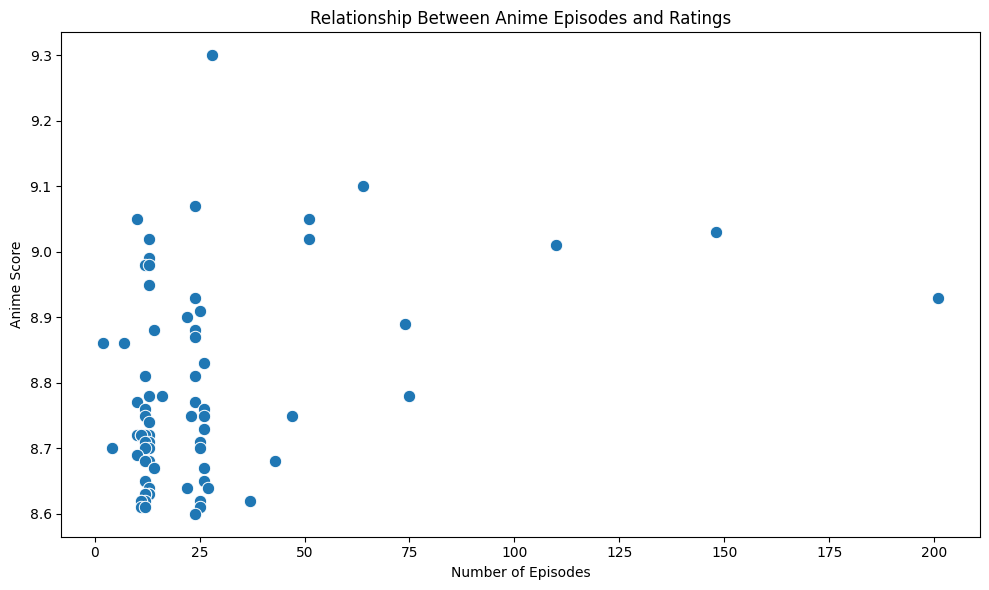

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='episodes',
    y='score',
    s=80
)

plt.title('Relationship Between Anime Episodes and Ratings')
plt.xlabel('Number of Episodes')
plt.ylabel('Anime Score')
plt.tight_layout()
plt.savefig('episodes_vs_ratings.png', dpi=300)
plt.show()

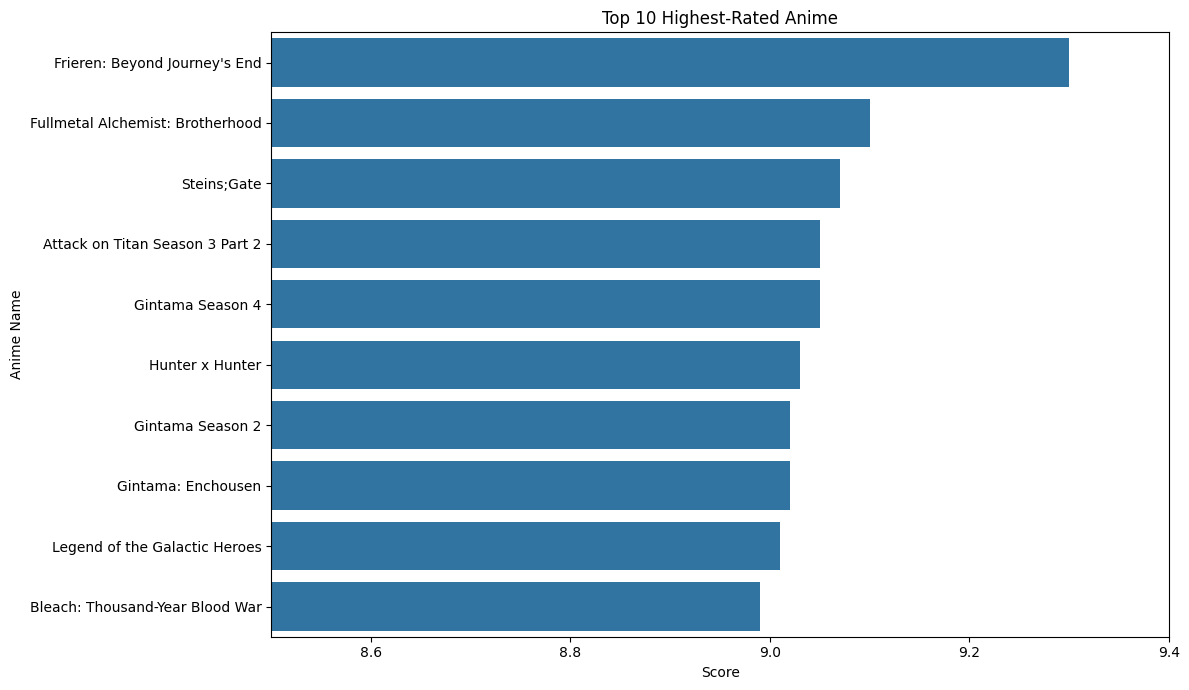

In [19]:
top_anime = (
    df.sort_values(by='score', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_anime['score'],
    y=top_anime['name']
)

plt.title('Top 10 Highest-Rated Anime')
plt.xlabel('Score')
plt.ylabel('Anime Name')
plt.xlim(df['score'].min() - 0.1, df['score'].max() + 0.1)
plt.tight_layout()
plt.savefig('top_anime_by_score.png')
plt.show()

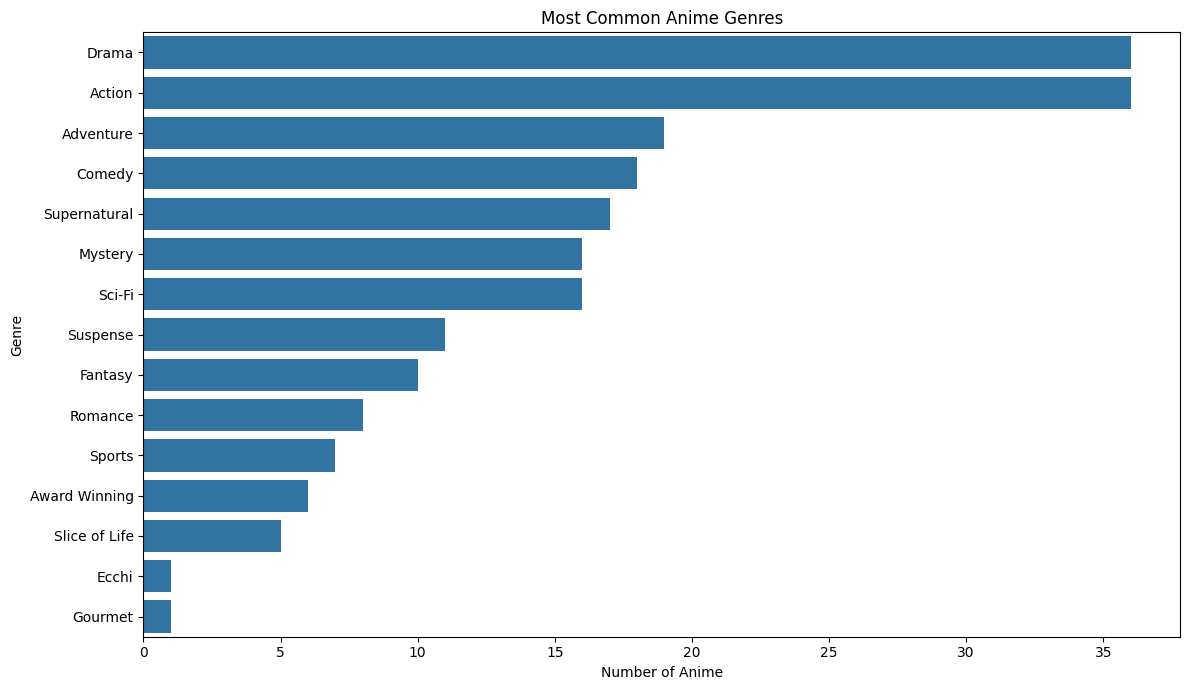

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

genre_data = df.assign(
    genre=df['genres'].str.split(', ')
)
genre_data = genre_data.explode('genre')
genre_counts = genre_data['genre'].value_counts()
plt.figure(figsize=(12, 7))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title('Most Common Anime Genres')
plt.xlabel('Number of Anime')
plt.ylabel('Genre')
plt.tight_layout()
plt.savefig('anime_genres.png', dpi=300)
plt.show()


In [16]:
print("ANIME SCORE STATISTICS")

print("Mean:", df['score'].mean())
print("Median:", df['score'].median())
print("Standard Deviation:", df['score'].std())

print("\nEPISODE STATISTICS")

print("Mean:", df['episodes'].mean())
print("Median:", df['episodes'].median())
print("Standard Deviation:", df['episodes'].std())


correlation = df['episodes'].corr(
    df['score']
)

print("Correlation between episodes and scores:", correlation)

ANIME SCORE STATISTICS
Mean: 8.778076923076924
Median: 8.725000000000001
Standard Deviation: 0.14907557302766444

EPISODE STATISTICS
Mean: 25.487179487179485
Median: 13.0
Standard Deviation: 30.169539807579646
Correlation between episodes and scores: 0.3591950244184524


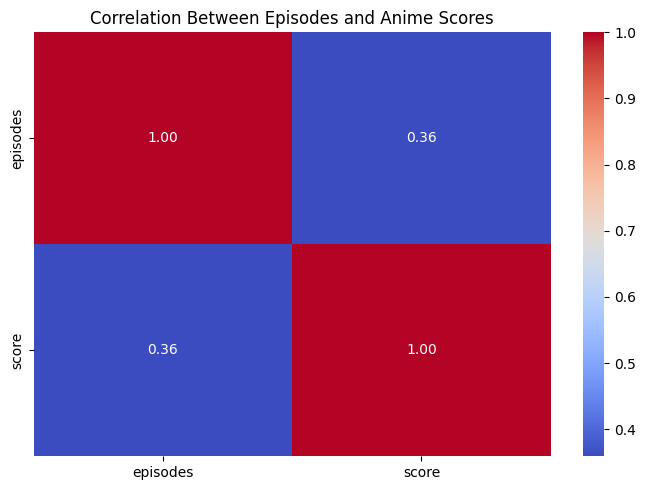

In [18]:
correlation_matrix = df[
    ['episodes', 'score']
].corr()
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Episodes and Anime Scores')

plt.tight_layout()

plt.savefig('correlation_heatmap.png', dpi=300)

plt.show()